# SOCAT training period comparison
Compare pCO2 predictions from the SOCAT-only ensemble trained on the full 1997–2024 record versus a restricted 2003–2024 record, evaluated over their common 2003–2024 overlap.

## 1. Load data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

socat_long = pd.read_csv("/remote/unity/bgc-output/DELAIGUE/SOCAT-FLOATS-SO-SINK-main/PREDICTION_MATRIX_v2/matrix_predictions/pco2_prediction_matrix_SOCAT_only_MCensemble.csv")
socat_short = pd.read_csv("/remote/unity/bgc-output/DELAIGUE/SOCAT-FLOATS-SO-SINK-main/PREDICTION_MATRIX_v2/matrix_predictions/pco2_prediction_matrix_SOCAT_only_MCensemble_2003_2024.csv")


## 2. Merge on the common 2003–2024 window and compute comparison stats

In [2]:
key_cols = ["latitude", "longitude", "month_center"]

# Restrict the long-training dataset to the 2003-2024 overlap
socat_long_sub = socat_long[socat_long["year"] >= 2003].copy()

merged = socat_long_sub.merge(
    socat_short,
    on=key_cols,
    suffixes=("_long", "_short"),
    how="inner"
)

print(f"n rows long (2003-2024 subset): {len(socat_long_sub)}")
print(f"n rows short: {len(socat_short)}")
print(f"n rows merged (matched): {len(merged)}")

merged["diff"] = merged["ensemble_pco2_pred_long"] - merged["ensemble_pco2_pred_short"]

stats = {
    "n_points": len(merged),
    "mean_diff": merged["diff"].mean(),
    "std_diff": merged["diff"].std(),
    "mean_abs_diff": merged["diff"].abs().mean(),
    "rmse": np.sqrt((merged["diff"]**2).mean()),
    "corr": merged["ensemble_pco2_pred_long"].corr(merged["ensemble_pco2_pred_short"]),
}
for k, v in stats.items():
    print(f"{k}: {v:.4f}" if isinstance(v, float) else f"{k}: {v}")


n rows long (2003-2024 subset): 2760918
n rows short: 2760918
n rows merged (matched): 2760918
n_points: 2760918
mean_diff: -0.1032
std_diff: 2.1587
mean_abs_diff: 1.2455
rmse: 2.1612
corr: 0.9959


## 3. Compare disagreement to the ensemble's own prediction uncertainty

In [3]:
print(merged["ensemble_pco2_std_long"].describe())
print(merged["ensemble_pco2_std_short"].describe())

# how big is the diff relative to the models' own uncertainty (absolute ratio)?
merged["diff_over_std"] = merged["diff"] / merged[["ensemble_pco2_std_long", "ensemble_pco2_std_short"]].mean(axis=1)
print(merged["diff_over_std"].abs().describe())


count    2.760918e+06
mean     6.081420e+00
std      3.573831e+00
min      1.162642e+00
25%      4.214453e+00
50%      5.404093e+00
75%      7.001090e+00
max      1.558820e+02
Name: ensemble_pco2_std_long, dtype: float64
count    2.760918e+06
mean     6.201292e+00
std      3.517143e+00
min      1.177205e+00
25%      4.295321e+00
50%      5.600385e+00
75%      7.193024e+00
max      1.549514e+02
Name: ensemble_pco2_std_short, dtype: float64
count    2.760918e+06
mean     1.993173e-01
std      2.138092e-01
min      0.000000e+00
25%      6.221224e-02
50%      1.366866e-01
75%      2.600900e-01
max      5.020088e+00
Name: diff_over_std, dtype: float64


## 4. Supplementary figure: 1:1 comparison scatter
x = long training (1997–2024), y = short training (2003–2024).

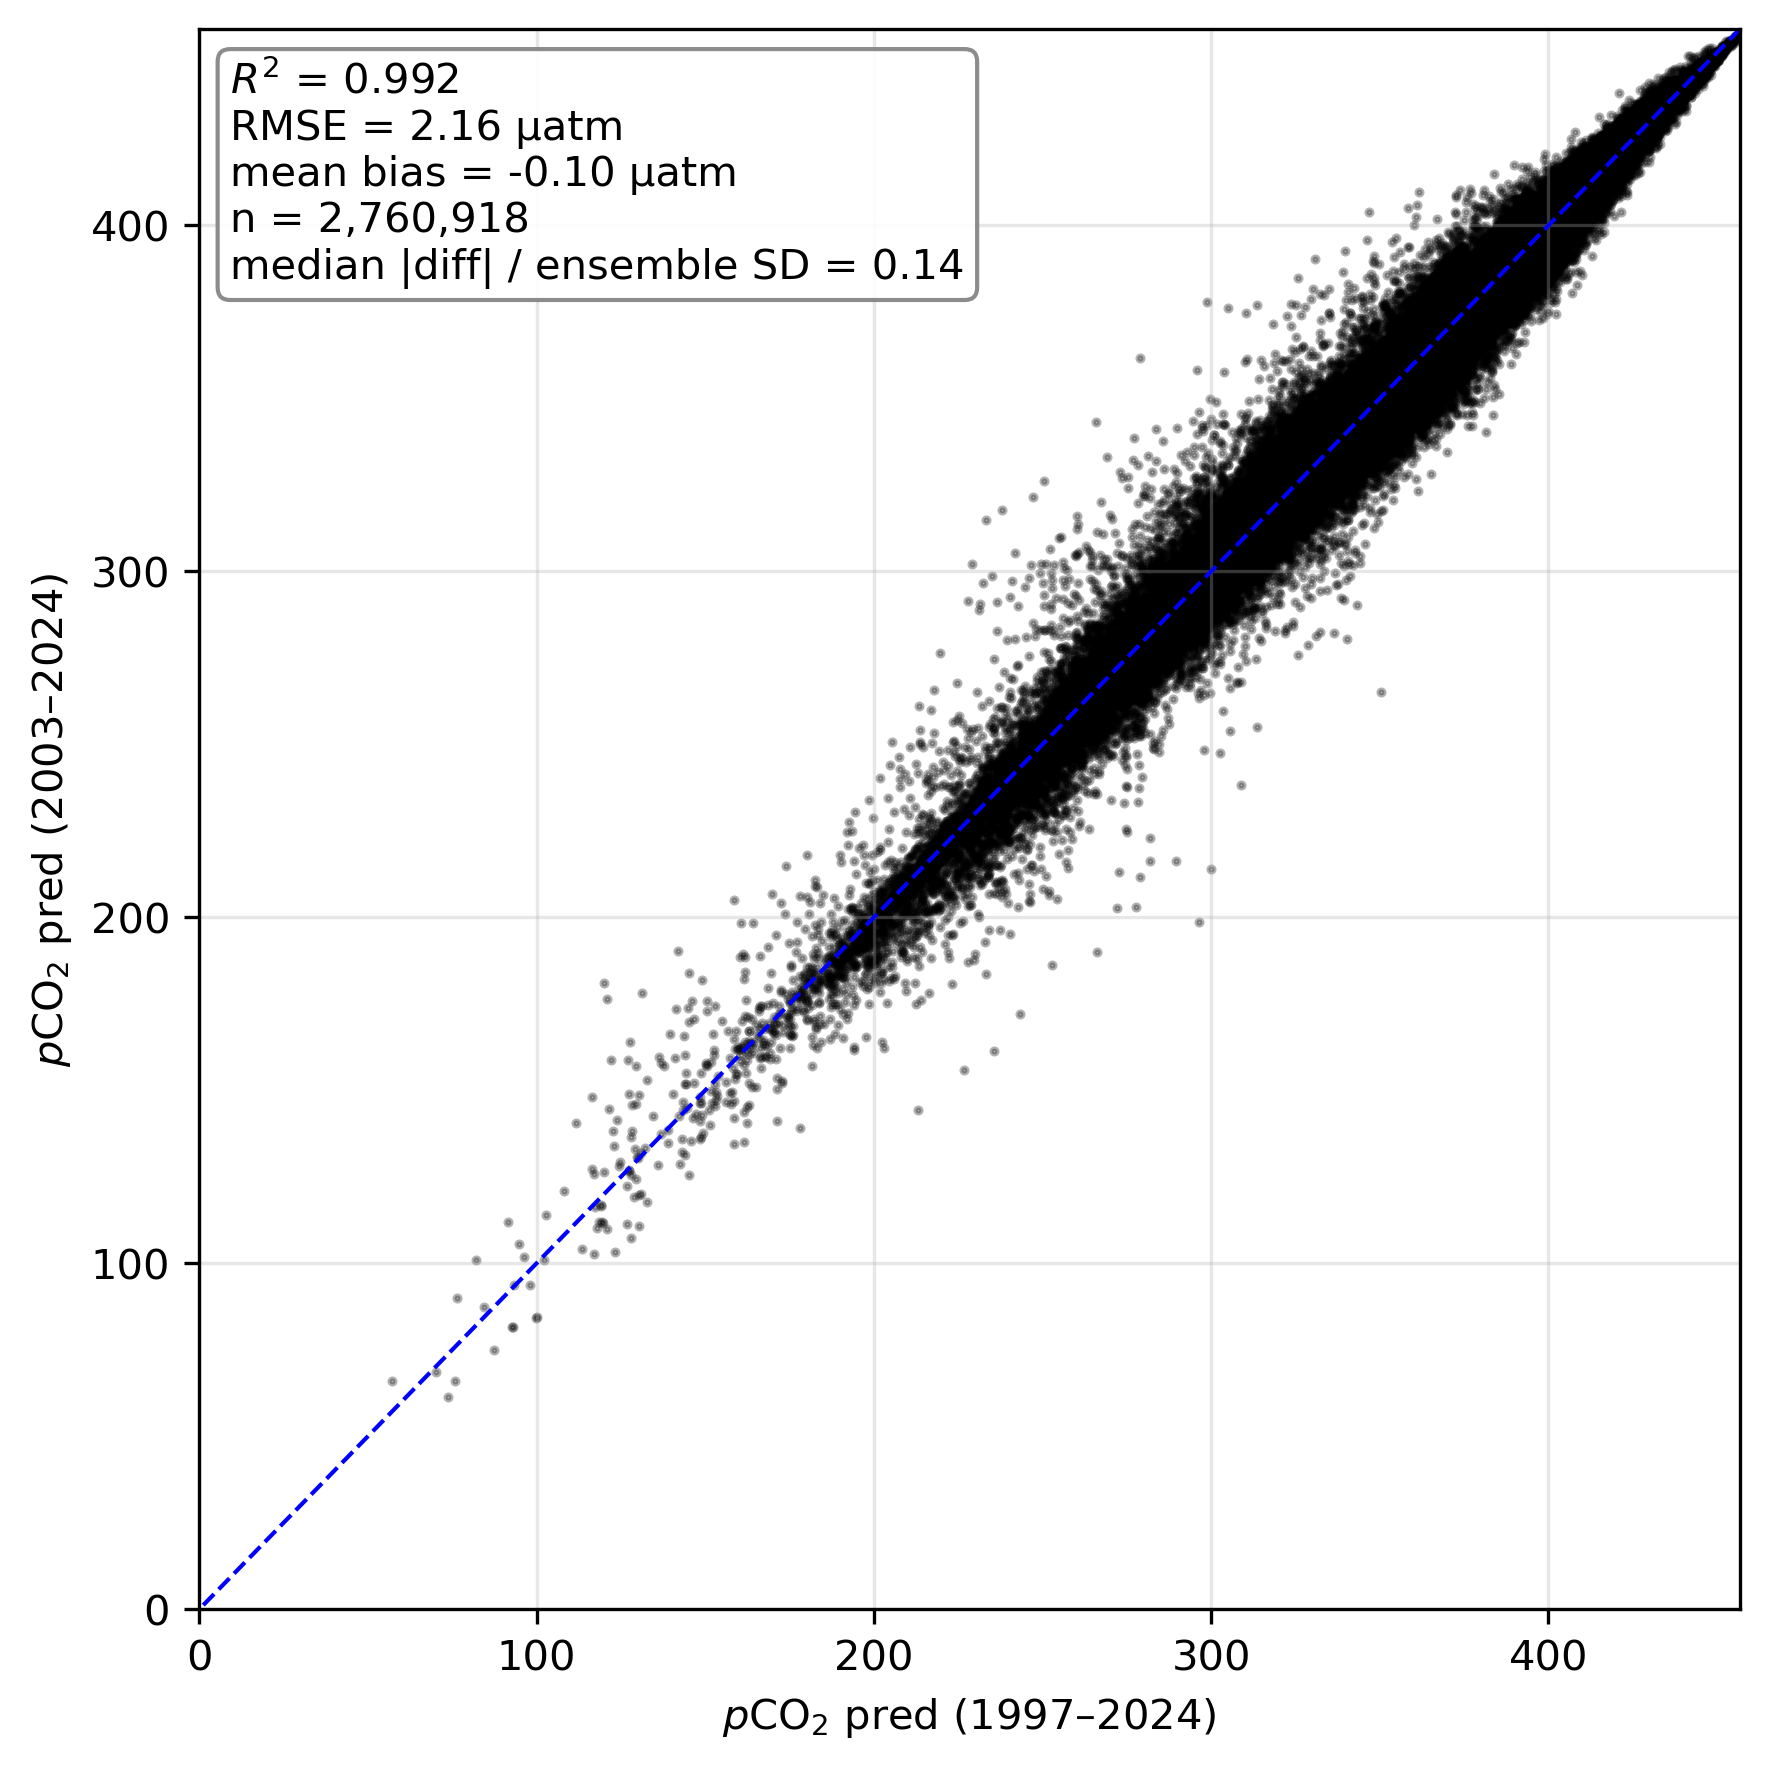

In [4]:
fig, ax = plt.subplots(figsize=(6, 6), dpi=300)

ax.scatter(merged["ensemble_pco2_pred_long"], merged["ensemble_pco2_pred_short"], s=2, alpha=0.3, c="k")

# 1:1 reference line, bounds taken from both columns so it spans the full data range
lo = merged[["ensemble_pco2_pred_short", "ensemble_pco2_pred_long"]].min().min()
hi = merged[["ensemble_pco2_pred_short", "ensemble_pco2_pred_long"]].max().max()
ax.plot([lo, hi], [lo, hi], 'b--', lw=1)

# italic p, subscript 2 via mathtext
ax.set_xlabel("$p$CO$_2$ pred (1997\u20132024)")
ax.set_ylabel("$p$CO$_2$ pred (2003\u20132024)")

# summary stats box, upper-left corner (axes-fraction coords, so it stays put regardless of data range)
stats_text = (
    f"$R^2$ = {stats['corr']**2:.3f}\n"
    f"RMSE = {stats['rmse']:.2f} \u00b5atm\n"
    f"mean bias = {stats['mean_diff']:.2f} \u00b5atm\n"
    f"n = {stats['n_points']:,}\n"
    f"median |diff| / ensemble SD = {merged['diff_over_std'].abs().median():.2f}"
)
ax.text(
    0.02, 0.98, stats_text,
    transform=ax.transAxes,
    verticalalignment='top',
    horizontalalignment='left',
    fontsize=10,
    bbox=dict(boxstyle="round", facecolor="white", edgecolor="gray", alpha=0.9)
)

ax.set_xlim(0, hi)
ax.set_ylim(0, hi)

ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("/remote/unity/bgc-output/DELAIGUE/SOCAT-FLOATS-SO-SINK-main/figs/Supp_fig_training_period_comparison.png", dpi=300, bbox_inches="tight")
plt.show()
